# TadGAN: Unsupervised Anomaly Detection

Unlike supervised models that try to predict `AC_POWER` from weather, a TadGAN learns the normal distribution of a full sequence (Weather + AC_POWER). Anomalies are identified when the model fails to reconstruct a sequence accurately or when the Critic flags it as 'fake'.

In [8]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from sklearn.preprocessing import StandardScaler

sys.path.append(os.path.abspath('..'))
from src.data_fusion import preprocess_pipeline
from src.models.baseline import prepare_data
from src.models.generative import TadGANDataset, train_tadgan, calculate_anomaly_scores

## Independent Domain Scaling

To transfer the TadGAN to Plant 2, we must scale Plant 2 independently. If we don't, its inherently lower physical capacity would constantly look like an anomaly compared to Plant 1.

In [9]:
# Load Data
plant1_gen_path = os.path.join('..', 'dataset', 'Plant_1_Generation_Data.csv')
plant1_weather_path = os.path.join('..', 'dataset', 'Plant_1_Weather_Sensor_Data.csv')
df_plant1 = preprocess_pipeline(plant1_gen_path, plant1_weather_path)

plant2_gen_path = os.path.join('..', 'dataset', 'Plant_2_Generation_Data.csv')
plant2_weather_path = os.path.join('..', 'dataset', 'Plant_2_Weather_Sensor_Data.csv')
df_plant2 = preprocess_pipeline(plant2_gen_path, plant2_weather_path)

# Extract Features & Target, then concatenate for multivariate reconstruction
X1_raw, y1_raw = prepare_data(df_plant1)
data_plant1 = pd.concat([X1_raw, y1_raw], axis=1).values

X2_raw, y2_raw = prepare_data(df_plant2)
data_plant2 = pd.concat([X2_raw, y2_raw], axis=1).values

# Independent Scalers
scaler1 = StandardScaler()
data_plant1_scaled = scaler1.fit_transform(data_plant1)

scaler2 = StandardScaler()
data_plant2_scaled = scaler2.fit_transform(data_plant2)

## Sequence Preparation

We convert our tabular data into sliding windows of length 16 (4 hours).

In [10]:
sequence_length = 16
batch_size = 64

# Plant 1 Dataset (Training)
dataset_p1 = TadGANDataset(data_plant1_scaled, sequence_length)
loader_p1 = DataLoader(dataset_p1, batch_size=batch_size, shuffle=True)

# Plant 2 Dataset (Inference)
# For plotting later, we isolate a single inverter to make the chart readable
inverter_id_p2 = df_plant2['INVERTER_ID'].iloc[0]
df_p2_single = df_plant2[df_plant2['INVERTER_ID'] == inverter_id_p2].copy()

X2_single, y2_single = prepare_data(df_p2_single)
data_p2_single = pd.concat([X2_single, y2_single], axis=1).values
data_p2_single_scaled = scaler2.transform(data_p2_single)  # Use Plant 2's scaler

dataset_p2_single = TadGANDataset(data_p2_single_scaled, sequence_length)
loader_p2_single = DataLoader(dataset_p2_single, batch_size=batch_size, shuffle=False)


## TadGAN Training (WGAN-GP)

We train the TadGAN on Plant 1. The Adversarial Minimax loop trains the Generator and Encoder against the Critics. This will take some time.

In [11]:
input_dim = data_plant1_scaled.shape[1]
print("Starting TadGAN training on Plant 1 (this may take a few minutes)...")

encoder, generator, cx, cz = train_tadgan(
    loader_p1, 
    input_dim=input_dim, 
    seq_len=sequence_length, 
    epochs=25,
    n_critic=2 # Lowered critic ratio for faster training
)
print("Training Complete!")

Starting TadGAN training on Plant 1 (this may take a few minutes)...
Epoch 1/25 | Cx: 0.1646 | Cz: -2.5957 | EG: 2.0854
Epoch 2/25 | Cx: -0.0477 | Cz: -2.2078 | EG: 2.5197
Epoch 3/25 | Cx: -0.1005 | Cz: -1.3567 | EG: 1.6377
Epoch 4/25 | Cx: -0.0271 | Cz: -0.9479 | EG: 4.3838
Epoch 5/25 | Cx: -0.0863 | Cz: -0.7641 | EG: 3.1959
Epoch 6/25 | Cx: -0.2006 | Cz: -0.7034 | EG: 3.6347
Epoch 7/25 | Cx: -0.1847 | Cz: -0.7360 | EG: 1.5959
Epoch 8/25 | Cx: -0.0066 | Cz: -0.7389 | EG: 6.1087
Epoch 9/25 | Cx: -0.0815 | Cz: -0.6046 | EG: 6.4490
Epoch 10/25 | Cx: -0.0283 | Cz: -0.3544 | EG: 7.7877
Epoch 11/25 | Cx: -0.0120 | Cz: -0.3761 | EG: 8.8432
Epoch 12/25 | Cx: -0.0661 | Cz: -0.3707 | EG: 7.1672
Epoch 13/25 | Cx: -0.0611 | Cz: -0.3395 | EG: 4.9384
Epoch 14/25 | Cx: -0.1068 | Cz: -0.3389 | EG: 5.0871
Epoch 15/25 | Cx: -0.0696 | Cz: -0.3660 | EG: 5.0812
Epoch 16/25 | Cx: -0.0479 | Cz: -0.3918 | EG: 7.4084
Epoch 17/25 | Cx: -0.0552 | Cz: -0.3760 | EG: 6.8370
Epoch 18/25 | Cx: 0.0428 | Cz: -0.3089 |

## Inference and Anomaly Detection (Plant 2)

We pass Plant 2 through the trained model. The anomaly score is a combination of Reconstruction Error and Critic X score.

In [12]:
# Calculate scores for Plant 2
anomaly_scores, reconstructions = calculate_anomaly_scores(encoder, generator, cx, loader_p2_single, alpha=0.5)

# Define an anomaly threshold dynamically (e.g. 98th percentile of anomaly scores)
threshold = np.percentile(anomaly_scores, 98)
is_anomaly = anomaly_scores > threshold

print(f"Threshold set at: {threshold:.4f}")
print(f"Detected {sum(is_anomaly)} anomalous sequences out of {len(anomaly_scores)}.")

Threshold set at: 0.5165
Detected 64 anomalous sequences out of 3179.


## Visualization

Plot the original AC Power for Plant 2 and highlight the anomalous regions in red.

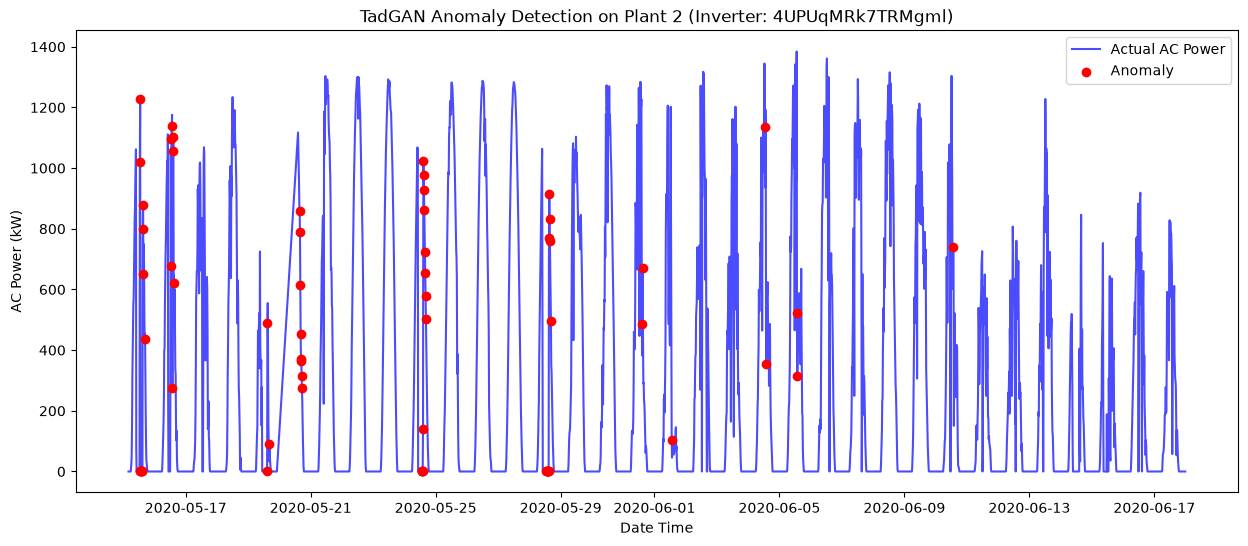

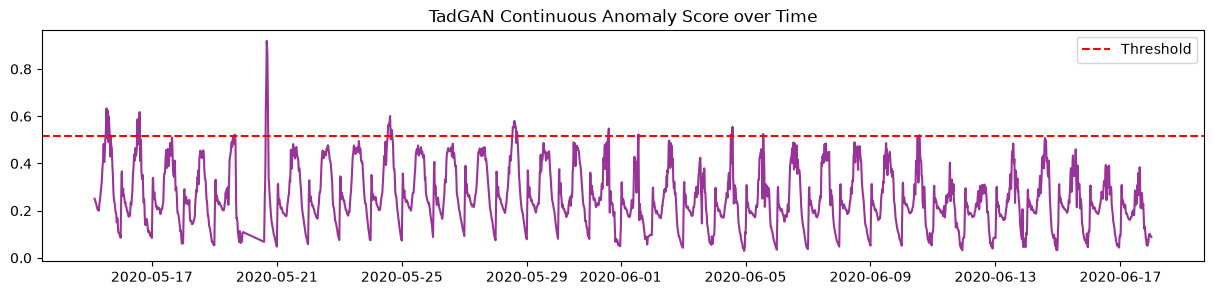

In [13]:
from matplotlib import transforms
# Align the dataframe with the sequences (first sequence_length rows are dropped)
plot_df = df_p2_single.iloc[sequence_length:].copy()
plot_df['ANOMALY_SCORE'] = anomaly_scores
plot_df['IS_ANOMALY'] = is_anomaly

# We want to reconstruct the AC_POWER for visualization (it was the last column in data_plant2)
# Inverse transform the reconstructions to get real kW
dummy_reconstructions = np.zeros((reconstructions.shape[0], data_plant1.shape[1]))
# The last element in the sequence, last feature (AC_POWER)
dummy_reconstructions[:, -1] = reconstructions[:, -1, -1] 
ac_power_reconstructed = scaler2.inverse_transform(dummy_reconstructions)[:, -1]
plot_df['RECONSTRUCTED_AC_POWER'] = ac_power_reconstructed

plt.figure(figsize=(15, 6))
plt.plot(plot_df['DATE_TIME'], plot_df['AC_POWER'], label='Actual AC Power', color='blue', alpha=0.7)

# Highlight anomalies
anomalous_data = plot_df[plot_df['IS_ANOMALY']]
plt.scatter(anomalous_data['DATE_TIME'], anomalous_data['AC_POWER'], color='red', label='Anomaly', zorder=5)


plt.title(f'TadGAN Anomaly Detection on Plant 2 (Inverter: {inverter_id_p2})')
plt.xlabel('Date Time')
plt.ylabel('AC Power (kW)')
plt.legend()
plt.show()

# Optional: Plot the anomaly score itself
plt.figure(figsize=(15, 3))
plt.plot(plot_df['DATE_TIME'], plot_df['ANOMALY_SCORE'], color='purple', alpha=0.8)
plt.axhline(y=threshold, color='r', linestyle='--', label='Threshold')
plt.title('TadGAN Continuous Anomaly Score over Time')
plt.legend()
plt.show()

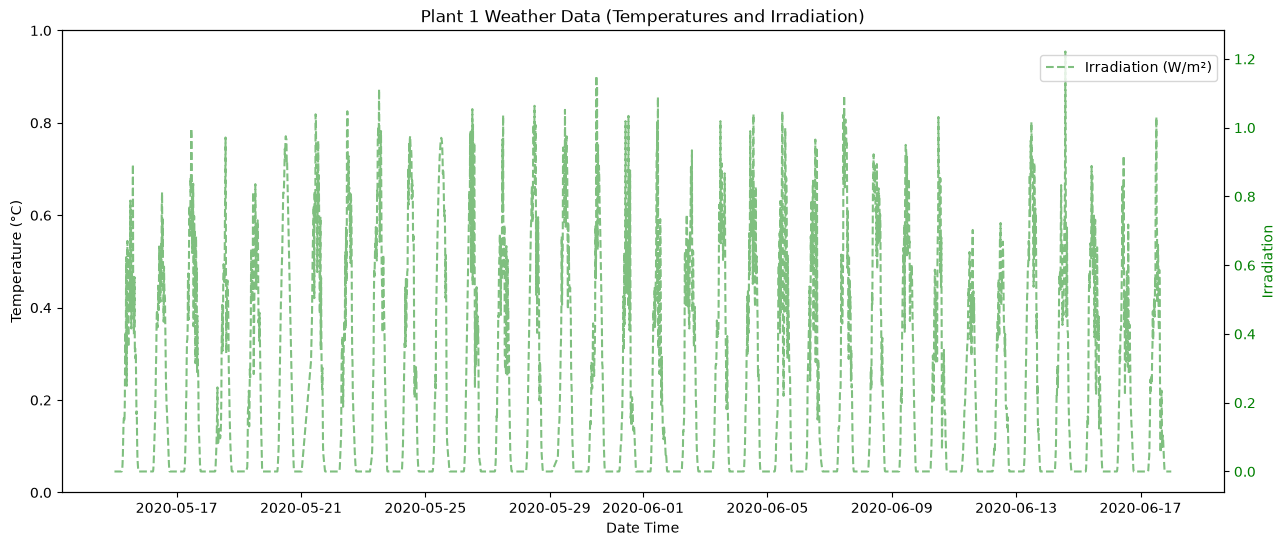

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the Plant 2 Weather Data
weather_p2 = pd.read_csv('../dataset/Plant_1_Weather_Sensor_Data.csv')

# 2. Convert DATE_TIME to actual datetime objects for proper plotting on the X-axis
weather_p2['DATE_TIME'] = pd.to_datetime(weather_p2['DATE_TIME'])

# 3. Create the plot
fig, ax1 = plt.subplots(figsize=(15, 6))

# Plot Temperatures on the primary Y-axis (left side)
# ax1.plot(weather_p2['DATE_TIME'], weather_p2['AMBIENT_TEMPERATURE'], label='Ambient Temp (Â°C)', color='blue', alpha=0.6)
# ax1.plot(weather_p2['DATE_TIME'], weather_p2['MODULE_TEMPERATURE'], label='Module Temp (Â°C)', color='orange', alpha=0.8)
ax1.set_xlabel('Date Time')
ax1.set_ylabel('Temperature (Â°C)', color='black')
ax1.tick_params(axis='y', labelcolor='black')

# Create a secondary Y-axis for Irradiation (right side)
ax2 = ax1.twinx()  
ax2.plot(weather_p2['DATE_TIME'], weather_p2['IRRADIATION'], label='Irradiation (W/mÂ²)', color='green', alpha=0.5, linestyle='--')
ax2.set_ylabel('Irradiation', color='green')
ax2.tick_params(axis='y', labelcolor='green')

# Add titles and legends
plt.title('Plant 1 Weather Data (Temperatures and Irradiation)')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.85))

plt.show()


In [15]:
print(anomalous_data['DATE_TIME'])

50     2020-05-15 12:30:00
51     2020-05-15 12:45:00
52     2020-05-15 13:00:00
53     2020-05-15 13:15:00
54     2020-05-15 13:30:00
               ...        
1902   2020-06-04 12:45:00
1907   2020-06-04 14:00:00
2001   2020-06-05 13:30:00
2002   2020-06-05 13:45:00
2481   2020-06-10 13:30:00
Name: DATE_TIME, Length: 64, dtype: datetime64[us]


In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.models.generative import TadGANDataset, calculate_anomaly_scores
from torch.utils.data import DataLoader

def evaluate_and_save_tadgan(df, plant_name, encoder, generator, cx, scaler, threshold, seq_len=16):
    save_dir = f"../results/{plant_name}_tadgan"
    os.makedirs(save_dir, exist_ok=True)
    
    plant_str = plant_name.capitalize()[:-1] + '_' + plant_name[-1]
    weather_df = pd.read_csv(f"../dataset/{plant_str}_Weather_Sensor_Data.csv")
    weather_df['DATE_TIME'] = pd.to_datetime(weather_df['DATE_TIME'])
    weather_df = weather_df.sort_values('DATE_TIME')
    
    inverters = df['INVERTER_ID'].unique()
    for inv in inverters:
        df_inv = df[df['INVERTER_ID'] == inv].copy()
        df_inv = df_inv.sort_values('DATE_TIME')
        
        features = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'TIME_OF_DAY']
        df_clean = df_inv.dropna(subset=features + ['AC_POWER']).copy()
        
        if len(df_clean) <= seq_len:
            continue
            
        X_inv_raw = df_clean[features].values
        y_inv_raw = df_clean['AC_POWER'].values
        data_inv = np.concatenate([X_inv_raw, y_inv_raw.reshape(-1, 1)], axis=1)
            
        data_inv_scaled = scaler.transform(data_inv)
        
        dataset = TadGANDataset(data_inv_scaled, seq_len)
        loader = DataLoader(dataset, batch_size=64, shuffle=False)
        
        anomaly_scores, _ = calculate_anomaly_scores(encoder, generator, cx, loader, alpha=0.5)
        is_anomaly = anomaly_scores > threshold
        
        df_clean = df_clean.iloc[seq_len:].copy()
        df_clean['ANOMALY_SCORE'] = anomaly_scores
        df_clean['IS_ANOMALY'] = is_anomaly
        
        plot_df = df_inv.set_index('DATE_TIME').resample('15min').asfreq().reset_index()
        plot_df = plot_df.merge(df_clean[['DATE_TIME', 'ANOMALY_SCORE', 'IS_ANOMALY']], on='DATE_TIME', how='left')
        plot_df['IS_ANOMALY'] = plot_df['IS_ANOMALY'].fillna(False)
        
        start_time = plot_df['DATE_TIME'].min()
        end_time = plot_df['DATE_TIME'].max()
        w_df = weather_df[(weather_df['DATE_TIME'] >= start_time) & (weather_df['DATE_TIME'] <= end_time)]
        
        # Plot 1: Power vs Anomalies vs Irradiation
        fig, ax1 = plt.subplots(figsize=(15, 6))
        ax1.plot(plot_df['DATE_TIME'], plot_df['AC_POWER'], label='Actual AC Power', color='blue', alpha=0.7)
        
        anomalous_data = plot_df[plot_df['IS_ANOMALY']]
        ax1.scatter(anomalous_data['DATE_TIME'], anomalous_data['AC_POWER'], color='red', label='Anomaly', zorder=5)
        ax1.set_xlabel('Date Time')
        ax1.set_ylabel('AC Power (kW)', color='black')
        
        ax2 = ax1.twinx()
        ax2.plot(w_df['DATE_TIME'], w_df['IRRADIATION'], label='Irradiation', color='green', alpha=0.3, linestyle='--')
        ax2.set_ylabel('Irradiation', color='green')
        
        plt.title(f"{plant_name.upper()} | Inverter: {inv} | TadGAN Anomalies")
        fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.85))
        plt.tight_layout()
        plt.savefig(f"{save_dir}/{inv}_anomalies.png")
        plt.close()
        
        # Plot 2: Anomaly Score Only
        plt.figure(figsize=(15, 3))
        plt.plot(plot_df['DATE_TIME'], plot_df['ANOMALY_SCORE'], color='purple', alpha=0.8)
        plt.axhline(y=threshold, color='r', linestyle='--', label='Threshold')
        plt.title(f"{plant_name.upper()} | Inverter: {inv} | Continuous Anomaly Score")
        plt.legend()
        plt.tight_layout()
        plt.savefig(f"{save_dir}/{inv}_scores.png")
        plt.close()

evaluate_and_save_tadgan(df_plant1, "plant1", encoder, generator, cx, scaler1, threshold)
evaluate_and_save_tadgan(df_plant2, "plant2", encoder, generator, cx, scaler2, threshold)
print("TadGAN plots saved in results/ directory!")


âœ… TadGAN plots saved in results/ directory!


In [19]:

import torch
import os

os.makedirs('../results/saved_models', exist_ok=True)

# 1. Save Models
torch.save(encoder.state_dict(), '../results/saved_models/tadgan_encoder.pt')
torch.save(generator.state_dict(), '../results/saved_models/tadgan_generator.pt')
torch.save(cx.state_dict(), '../results/saved_models/tadgan_cx.pt')
torch.save(cz.state_dict(), '../results/saved_models/tadgan_cz.pt')

# 2. Save Anomaly Scores
# plot_df contains the plant 2 scores
plot_df.to_csv('../results/tadgan_plant2_anomalies.csv', index=False)
print("TadGAN models and anomaly scores saved successfully!")


TadGAN models and anomaly scores saved successfully!


## Generate Plant 1 Anomalies CSV (from saved model)

Load the saved TadGAN weights and run inference over Plant 1 to produce
`results/tadgan_plant1_anomalies.csv` with the same schema as the Plant 2 file.

In [ ]:
import sys, os, torch, numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader

sys.path.append(os.path.abspath('..'))
from src.data_fusion import preprocess_pipeline
from src.models.baseline import prepare_data
from src.models.generative import (
    TadGANDataset, calculate_anomaly_scores,
    Encoder, Generator, CriticX, CriticZ
)

# Hyperparameters matching training
seq_len    = 16
latent_dim = 20
hidden_dim = 64

# 1. Load Plant 1 data and fit scaler
plant1_gen_path     = os.path.join('..', 'dataset', 'Plant_1_Generation_Data.csv')
plant1_weather_path = os.path.join('..', 'dataset', 'Plant_1_Weather_Sensor_Data.csv')
df_plant1 = preprocess_pipeline(plant1_gen_path, plant1_weather_path)

X1_raw, y1_raw = prepare_data(df_plant1)
data_plant1 = pd.concat([X1_raw, y1_raw], axis=1).values
scaler1 = StandardScaler()
data_plant1_scaled = scaler1.fit_transform(data_plant1)
input_dim = data_plant1_scaled.shape[1]

# 2. Instantiate and load saved weights
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

enc = Encoder(input_dim, hidden_dim, latent_dim).to(device)
gen = Generator(latent_dim, hidden_dim, input_dim, seq_len).to(device)
cx  = CriticX(input_dim, hidden_dim).to(device)
cz  = CriticZ(latent_dim, hidden_dim).to(device)

enc.load_state_dict(torch.load('../results/saved_models/tadgan_encoder.pt',   map_location=device))
gen.load_state_dict(torch.load('../results/saved_models/tadgan_generator.pt', map_location=device))
cx.load_state_dict( torch.load('../results/saved_models/tadgan_cx.pt',        map_location=device))
cz.load_state_dict( torch.load('../results/saved_models/tadgan_cz.pt',        map_location=device))
enc.eval(); gen.eval(); cx.eval(); cz.eval()
print('Model weights loaded')

# 3. Global threshold from all Plant 1 sequences
dataset_p1_full = TadGANDataset(data_plant1_scaled, seq_len)
loader_p1_full  = DataLoader(dataset_p1_full, batch_size=64, shuffle=False)
all_scores_p1, _ = calculate_anomaly_scores(enc, gen, cx, loader_p1_full, alpha=0.5)
threshold_p1 = np.percentile(all_scores_p1, 98)
print(f'Plant 1 anomaly threshold (98th pct): {threshold_p1:.4f}')

# 4. Per-inverter inference
features = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'TIME_OF_DAY']
rows = []

for inv in df_plant1['INVERTER_ID'].unique():
    df_inv   = df_plant1[df_plant1['INVERTER_ID'] == inv].sort_values('DATE_TIME')
    df_clean = df_inv.dropna(subset=features + ['AC_POWER']).copy()
    if len(df_clean) <= seq_len:
        continue

    X_inv = df_clean[features].values
    y_inv = df_clean['AC_POWER'].values
    data_inv = np.concatenate([X_inv, y_inv.reshape(-1, 1)], axis=1)
    data_inv_scaled = scaler1.transform(data_inv)

    dataset = TadGANDataset(data_inv_scaled, seq_len)
    loader  = DataLoader(dataset, batch_size=64, shuffle=False)

    scores, recons = calculate_anomaly_scores(enc, gen, cx, loader, alpha=0.5)
    is_anomaly = scores > threshold_p1

    df_result = df_clean.iloc[seq_len:].copy()
    df_result['ANOMALY_SCORE']          = scores
    df_result['IS_ANOMALY']             = is_anomaly
    df_result['RECONSTRUCTED_AC_POWER'] = recons[:, -1, -1]  # last timestep, AC_POWER col
    rows.append(df_result)

plant1_anomalies = pd.concat(rows)
plant1_anomalies.to_csv('../results/tadgan_plant1_anomalies.csv', index=False)
print(f'Saved tadgan_plant1_anomalies.csv  ({len(plant1_anomalies)} rows)')


Model weights loaded
Plant 1 anomaly threshold (98th pct): 0.5053
Saved tadgan_plant1_anomalies.csv  (68426 rows)


In [1]:
import sys, os, torch, numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader

sys.path.append(os.path.abspath('..'))
from src.data_fusion import preprocess_pipeline
from src.models.baseline import prepare_data
from src.models.generative import (
    TadGANDataset, calculate_anomaly_scores,
    Encoder, Generator, CriticX, CriticZ
)

# Hyperparameters matching training
seq_len    = 16
latent_dim = 20
hidden_dim = 64

# 1. Load Plant 1 data and fit scaler
plant1_gen_path     = os.path.join('..', 'dataset', 'Plant_2_Generation_Data.csv')
plant1_weather_path = os.path.join('..', 'dataset', 'Plant_2_Weather_Sensor_Data.csv')
df_plant1 = preprocess_pipeline(plant1_gen_path, plant1_weather_path)

X1_raw, y1_raw = prepare_data(df_plant1)
data_plant1 = pd.concat([X1_raw, y1_raw], axis=1).values
scaler1 = StandardScaler()
data_plant1_scaled = scaler1.fit_transform(data_plant1)
input_dim = data_plant1_scaled.shape[1]

# 2. Instantiate and load saved weights
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

enc = Encoder(input_dim, hidden_dim, latent_dim).to(device)
gen = Generator(latent_dim, hidden_dim, input_dim, seq_len).to(device)
cx  = CriticX(input_dim, hidden_dim).to(device)
cz  = CriticZ(latent_dim, hidden_dim).to(device)

enc.load_state_dict(torch.load('../results/saved_models/tadgan_encoder.pt',   map_location=device))
gen.load_state_dict(torch.load('../results/saved_models/tadgan_generator.pt', map_location=device))
cx.load_state_dict( torch.load('../results/saved_models/tadgan_cx.pt',        map_location=device))
cz.load_state_dict( torch.load('../results/saved_models/tadgan_cz.pt',        map_location=device))
enc.eval(); gen.eval(); cx.eval(); cz.eval()
print('Model weights loaded')

# 3. Global threshold from all Plant 1 sequences
dataset_p1_full = TadGANDataset(data_plant1_scaled, seq_len)
loader_p1_full  = DataLoader(dataset_p1_full, batch_size=64, shuffle=False)
all_scores_p1, _ = calculate_anomaly_scores(enc, gen, cx, loader_p1_full, alpha=0.5)
threshold_p1 = np.percentile(all_scores_p1, 98)
print(f'Plant 2 anomaly threshold (98th pct): {threshold_p1:.4f}')

# 4. Per-inverter inference
features = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'TIME_OF_DAY']
rows = []

for inv in df_plant1['INVERTER_ID'].unique():
    df_inv   = df_plant1[df_plant1['INVERTER_ID'] == inv].sort_values('DATE_TIME')
    df_clean = df_inv.dropna(subset=features + ['AC_POWER']).copy()
    if len(df_clean) <= seq_len:
        continue

    X_inv = df_clean[features].values
    y_inv = df_clean['AC_POWER'].values
    data_inv = np.concatenate([X_inv, y_inv.reshape(-1, 1)], axis=1)
    data_inv_scaled = scaler1.transform(data_inv)

    dataset = TadGANDataset(data_inv_scaled, seq_len)
    loader  = DataLoader(dataset, batch_size=64, shuffle=False)

    scores, recons = calculate_anomaly_scores(enc, gen, cx, loader, alpha=0.5)
    is_anomaly = scores > threshold_p1

    df_result = df_clean.iloc[seq_len:].copy()
    df_result['ANOMALY_SCORE']          = scores
    df_result['IS_ANOMALY']             = is_anomaly
    df_result['RECONSTRUCTED_AC_POWER'] = recons[:, -1, -1]  # last timestep, AC_POWER col
    rows.append(df_result)

plant1_anomalies = pd.concat(rows)
plant1_anomalies.to_csv('../results/tadgan_plant2_anomalies.csv', index=False)
print(f'Saved tadgan_plant2_anomalies.csv  ({len(plant1_anomalies)} rows)')


Model weights loaded
Plant 2 anomaly threshold (98th pct): 0.5074
Saved tadgan_plant2_anomalies.csv  (67346 rows)
